# 06 · Final evaluation

Brings every model together. It scores each prediction file in `results/` with `src/evaluate.py`, measures how much each score could move by chance, compares slang-heavy and plain posts, checks which models learned the author tags, and looks at the posts every model gets wrong.

- **Inputs:** `results/preds_*.csv` (notebooks 03 to 05), `data/test_hand_labeled.csv` (notebook 02) and `results/lora_log.csv` (notebook 05)
- **Outputs:** `results/metrics.csv` and the figures in `results/figures/`

Runs on the Mac in under a minute.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

# Let the notebook import our shared code from src/
ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from src.evaluate import RESULTS_DIR, bootstrap_macro_f1, evaluate, load_preds, load_test, test_with_preds
from src.labels import LABELS

FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

# Every model, in the order the stages built them, with the names used in tables and figures
MODELS = {
    "author_tag": "Author tags",
    "vader": "VADER",
    "finbert": "FinBERT",
    "cryptobert": "CryptoBERT*",
    "llm_zeroshot": "LLM zero-shot",
    "llm_fewshot": "LLM few-shot",
    "llm_lora": "LLM + LoRA",
}
LLMS = ["llm_zeroshot", "llm_fewshot", "llm_lora"]
GROUPS = ["all", "slang-heavy", "plain"]

# Check that no prediction file is left out
found = sorted(path.stem.removeprefix("preds_") for path in RESULTS_DIR.glob("preds_*.csv"))
assert found == sorted(MODELS), f"prediction files and MODELS differ: {found}"

test = load_test()

Every figure uses the same colors and style. The figures are saved to `results/figures/` for the README and the slides.

In [2]:
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#c9c8c1"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": MUTED,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": INK,
    "legend.frameon": False,
})


def save(fig, name):
    """Save a figure to results/figures/."""
    fig.savefig(FIGURES_DIR / name, dpi=200, bbox_inches="tight")

## 1. Scores

Every prediction file scored against the 300 hand-labeled posts. **Macro-F1** is the average of the F1 scores of the three labels, so each label counts equally; always answering neutral would score 0.23.

The table saved to `results/metrics.csv` also holds each score's 95% range (section 2), the F1 of each label (section 4) and the score against the author tags instead of the hand labels (section 5).

\*CryptoBERT was trained on posts from the same StockTwits dataset, so its scores are likely optimistic.

In [3]:
rows = []
resampled = {}  # macro-F1 on 1,000 resamples, per model and group (section 2)
for model in MODELS:
    vs_hand = evaluate(model)
    vs_author = evaluate(model, truth="author_label")
    for group in GROUPS:
        scores = vs_hand[group]
        resampled[model, group] = bootstrap_macro_f1(model, group)
        low, high = np.percentile(resampled[model, group], [2.5, 97.5])
        f1 = scores["per_class"]["f1"]
        rows.append({
            "model": model,
            "group": group,
            "posts": scores["posts"],
            "macro_f1": scores["macro_f1"],
            "macro_f1_low": low,
            "macro_f1_high": high,
            "accuracy": scores["accuracy"],
            "invalid_rate": scores["invalid_rate"],
            "f1_bullish": f1["bullish"],
            "f1_bearish": f1["bearish"],
            "f1_neutral": f1["neutral"],
            "macro_f1_vs_author_tags": vs_author[group]["macro_f1"],
        })

metrics = pd.DataFrame(rows)
metrics.round(4).to_csv(RESULTS_DIR / "metrics.csv", index=False)


def by_model(column):
    """One row per model and one column per group, for a column of the metrics table."""
    table = metrics.pivot(index="model", columns="group", values=column)
    return table.loc[list(MODELS), GROUPS]


by_model("macro_f1").rename(index=MODELS).round(3)

group,all,slang-heavy,plain
model,,,
Author tags,0.453,0.502,0.403
VADER,0.396,0.402,0.382
FinBERT,0.366,0.298,0.421
CryptoBERT*,0.466,0.475,0.441
LLM zero-shot,0.517,0.501,0.521
LLM few-shot,0.538,0.536,0.534
LLM + LoRA,0.494,0.511,0.471


Invalid-output rate for the three LLM runs (the other models always return a label):

In [4]:
by_model("invalid_rate").loc[LLMS].rename(index=MODELS)

group,all,slang-heavy,plain
model,,,
LLM zero-shot,0.0,0.0,0.0
LLM few-shot,0.0,0.0,0.0
LLM + LoRA,0.0,0.0,0.0


## 2. How much could the scores move?

The test set is one sample of 300 posts. With a different 300, every score would come out a little different. **Bootstrapping** estimates by how much:

1. Draw 300 posts at random from the test set *with replacement*, so some posts appear twice and some not at all.
2. Score the model on that resample.
3. Repeat 1,000 times. The middle 95% of the 1,000 scores is the model's **95% range**.

Every model is scored on the same 1,000 resamples, so two models can also be compared resample by resample. If A beats B in nearly every resample, the gap is real. If it only wins 70 to 80% of them, 300 posts are too few to tell.

In [5]:
overall = metrics[metrics["group"] == "all"].set_index("model")
overall[["macro_f1", "macro_f1_low", "macro_f1_high"]].rename(index=MODELS).round(3)

,macro_f1,macro_f1_low,macro_f1_high
model,,,
Author tags,0.453,0.394,0.510
VADER,0.396,0.330,0.454
FinBERT,0.366,0.311,0.419
CryptoBERT*,0.466,0.410,0.518
LLM zero-shot,0.517,0.461,0.569
LLM few-shot,0.538,0.481,0.596
LLM + LoRA,0.494,0.441,0.549


In [6]:
PAIRS = [
    ("llm_fewshot", "cryptobert"),
    ("llm_zeroshot", "cryptobert"),
    ("llm_lora", "cryptobert"),
    ("llm_fewshot", "llm_zeroshot"),
    ("llm_zeroshot", "llm_lora"),
    ("cryptobert", "author_tag"),
]
comparisons = []
for a, b in PAIRS:
    wins = (resampled[a, "all"] > resampled[b, "all"]).mean()
    comparisons.append({"model A": MODELS[a], "model B": MODELS[b], "A beats B in": f"{wins:.0%} of resamples"})
pd.DataFrame(comparisons)

,model A,model B,A beats B in
0,LLM few-shot,CryptoBERT*,98% of resamples
1,LLM zero-shot,CryptoBERT*,95% of resamples
2,LLM + LoRA,CryptoBERT*,85% of resamples
3,LLM few-shot,LLM zero-shot,75% of resamples
4,LLM zero-shot,LLM + LoRA,74% of resamples
5,CryptoBERT*,Author tags,69% of resamples


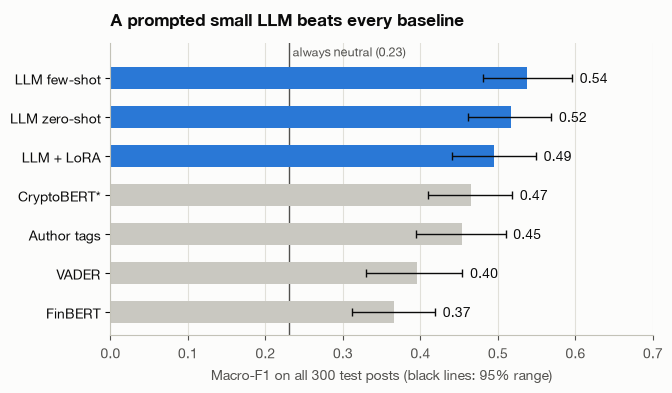

In [7]:
order = overall["macro_f1"].sort_values().index  # best at the top
y = np.arange(len(order))
scores = overall.loc[order]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axvline(0.23, color=MUTED, linewidth=1, zorder=1)
ax.text(0.235, len(order) - 0.45, "always neutral (0.23)", color=MUTED, fontsize=9)
ax.barh(y, scores["macro_f1"], height=0.55, color=[BLUE if model in LLMS else GRAY for model in order], zorder=2)
ax.errorbar(
    scores["macro_f1"], y,
    xerr=[scores["macro_f1"] - scores["macro_f1_low"], scores["macro_f1_high"] - scores["macro_f1"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3,
)
for i, model in enumerate(order):
    ax.text(scores.loc[model, "macro_f1_high"] + 0.01, i, f"{scores.loc[model, 'macro_f1']:.2f}", va="center")
ax.set_yticks(y, [MODELS[model] for model in order])
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xlim(0, 0.7)
ax.set_xlabel("Macro-F1 on all 300 test posts (black lines: 95% range)")
ax.grid(axis="y", visible=False)
ax.set_title("A prompted small LLM beats every baseline")
save(fig, "macro_f1_by_model.png")

## 3. Slang-heavy vs. plain posts

The research question asks whether the gap between models changes on slang. Each group has about 150 posts, so group scores can move more than overall scores (see the ranges below), and bearish has only about 30 posts per group.

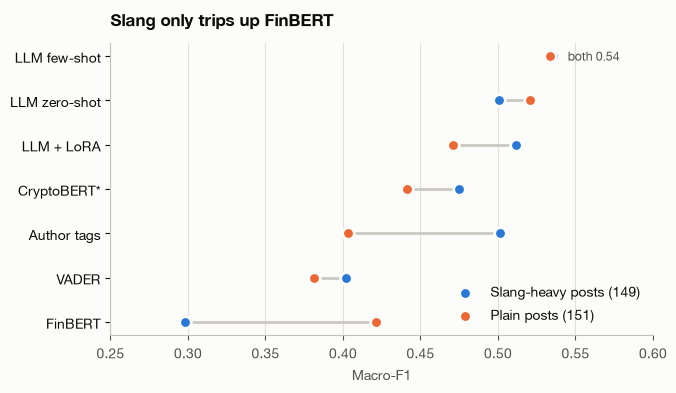

In [8]:
group_scores = by_model("macro_f1").loc[order]

fig, ax = plt.subplots(figsize=(7, 3.8))
for i, model in enumerate(order):
    ax.plot(group_scores.loc[model, ["slang-heavy", "plain"]], [i, i], color=GRAY, linewidth=2, zorder=1)
ax.scatter(group_scores["slang-heavy"], y, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=2, label="Slang-heavy posts (149)")
ax.scatter(group_scores["plain"], y, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=2, label="Plain posts (151)")
few_shot_row = list(order).index("llm_fewshot")
ax.text(0.545, few_shot_row, "both 0.54", va="center", color=MUTED, fontsize=9)  # the two dots overlap
ax.set_yticks(y, [MODELS[model] for model in order])
ax.set_xlim(0.25, 0.6)
ax.set_xlabel("Macro-F1")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Slang only trips up FinBERT")
save(fig, "slang_vs_plain.png")

The 95% ranges for each group:

In [9]:
ranges = by_model("macro_f1_low").round(2).astype(str) + " to " + by_model("macro_f1_high").round(2).astype(str)
ranges[["slang-heavy", "plain"]].rename(index=MODELS)

group,slang-heavy,plain
model,,
Author tags,0.42 to 0.58,0.32 to 0.48
VADER,0.32 to 0.47,0.3 to 0.45
FinBERT,0.23 to 0.37,0.34 to 0.5
CryptoBERT*,0.4 to 0.55,0.36 to 0.52
LLM zero-shot,0.43 to 0.57,0.44 to 0.59
LLM few-shot,0.45 to 0.61,0.44 to 0.61
LLM + LoRA,0.43 to 0.59,0.39 to 0.54


## 4. What each model predicts

How often each model answers each label, next to the hand labels:

,bullish,neutral,bearish
Hand labels,0.26,0.53,0.21
Author tags,0.33,0.33,0.33
VADER,0.35,0.35,0.30
FinBERT,0.03,0.84,0.13
CryptoBERT*,0.44,0.20,0.36
LLM zero-shot,0.51,0.12,0.37
LLM few-shot,0.17,0.30,0.53
LLM + LoRA,0.42,0.16,0.42


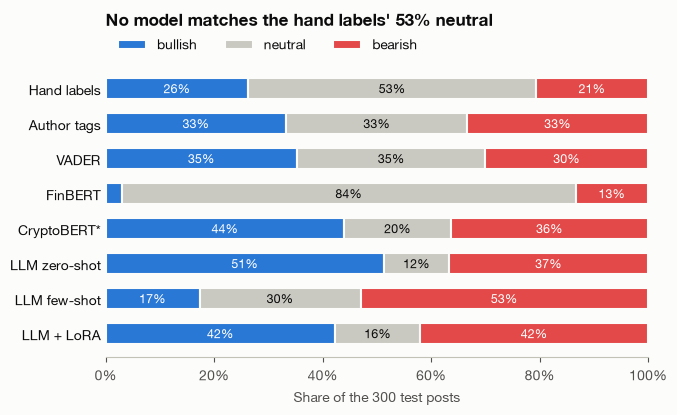

In [10]:
mix = {"Hand labels": test["label"].value_counts(normalize=True)}
for model, name in MODELS.items():
    mix[name] = test_with_preds(model)["pred_label"].value_counts(normalize=True)
mix = pd.DataFrame(mix).T.reindex(columns=["bullish", "neutral", "bearish"]).fillna(0)

fig, ax = plt.subplots(figsize=(7, 3.8))
left = np.zeros(len(mix))
for label, color in [("bullish", BLUE), ("neutral", GRAY), ("bearish", RED)]:
    shares = mix[label].to_numpy()
    ax.barh(mix.index, shares, left=left, height=0.6, color=color, edgecolor=SURFACE, linewidth=1.5, label=label)
    for i, share in enumerate(shares):
        if share >= 0.08:  # label only the segments wide enough to hold it
            ax.text(left[i] + share / 2, i, f"{share:.0%}", ha="center", va="center", fontsize=9,
                    color=INK if label == "neutral" else "white")
    left += shares
ax.invert_yaxis()  # hand labels on top
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.set_xlabel("Share of the 300 test posts")
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("No model matches the hand labels' 53% neutral", pad=28)
save(fig, "prediction_mix.png")

mix.round(2)

F1 for each label on all posts. Neutral is the weakest label for CryptoBERT, zero-shot and the fine-tune; few-shot does best on it of the three LLM runs:

In [11]:
overall[["f1_bullish", "f1_bearish", "f1_neutral"]].loc[list(MODELS)].rename(index=MODELS).round(3)

,f1_bullish,f1_bearish,f1_neutral
model,,,
Author tags,0.458,0.469,0.432
VADER,0.368,0.395,0.426
FinBERT,0.136,0.294,0.668
CryptoBERT*,0.559,0.480,0.358
LLM zero-shot,0.644,0.558,0.349
LLM few-shot,0.534,0.507,0.573
LLM + LoRA,0.592,0.532,0.359


Confusion matrices on all posts. Rows are the hand labels and columns the predictions; the numbers are post counts, and the shading shows the share of each row. A perfect model would have dark cells only on the diagonal. No model gave an invalid answer, so the `INVALID` column is left out.

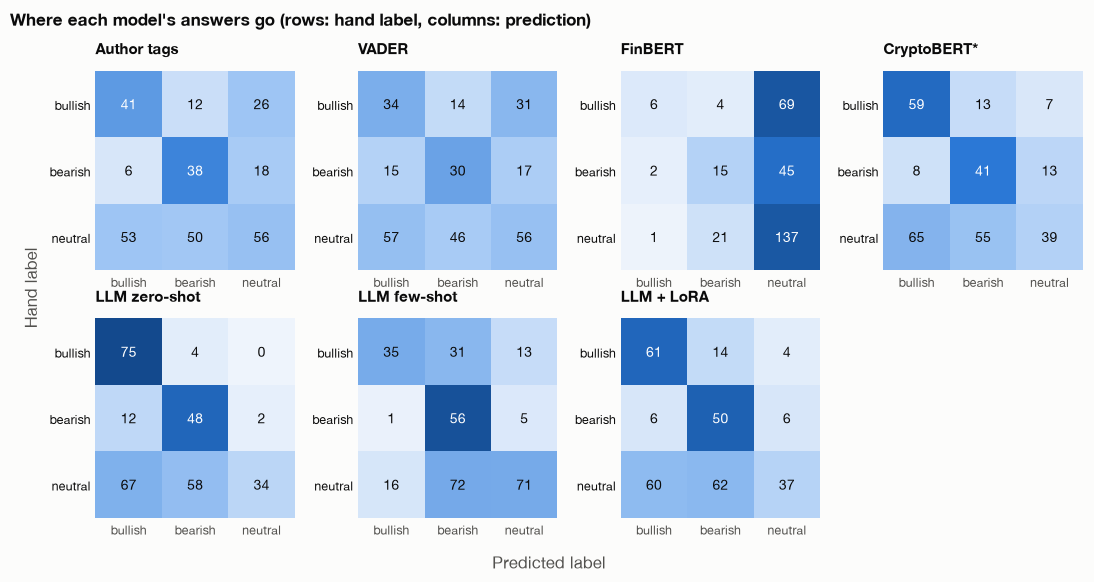

In [12]:
blues = LinearSegmentedColormap.from_list("blues", ["#eef4fc", "#9ec5f4", "#2a78d6", "#104281"])

fig, axes = plt.subplots(2, 4, figsize=(11, 5.8))
for ax, model in zip(axes.flat, MODELS):
    matrix = evaluate(model)["all"]["confusion"][LABELS]
    row_shares = matrix.div(matrix.sum(axis=1), axis=0)
    ax.imshow(row_shares, cmap=blues, vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, matrix.iloc[i, j], ha="center", va="center", color="white" if row_shares.iloc[i, j] > 0.5 else INK)
    ax.set_xticks(range(len(LABELS)), LABELS, fontsize=9)
    ax.set_yticks(range(len(LABELS)), LABELS, fontsize=9)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(MODELS[model], fontsize=11)
axes.flat[-1].axis("off")
fig.supxlabel("Predicted label", color=MUTED)
fig.supylabel("Hand label", color=MUTED)
fig.suptitle("Where each model's answers go (rows: hand label, columns: prediction)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "confusion_matrices.png")

## 5. Which models learned the author tags?

The training data's labels are the authors' own tags. First, how often do those tags match the hand labels? Rows are the author tags and columns the hand labels:

In [13]:
print(f"Author tag matches the hand label on {(test['author_label'] == test['label']).mean():.0%} of test posts")
pd.crosstab(test["author_label"], test["label"], rownames=["author tag"], colnames=["hand label"])

Author tag matches the hand label on 45% of test posts


hand label,bearish,bullish,neutral
author tag,,,
bearish,38,12,50
bullish,6,41,53
neutral,18,26,56


Now each model is scored twice: against the hand labels, as everywhere else, and against the author tags. A model that learned to copy the tags scores much higher against them.

,vs. hand labels,vs. author tags
model,,
CryptoBERT*,0.466,0.717
LLM + LoRA,0.494,0.586
LLM zero-shot,0.517,0.439
LLM few-shot,0.538,0.422
VADER,0.396,0.367
FinBERT,0.366,0.272


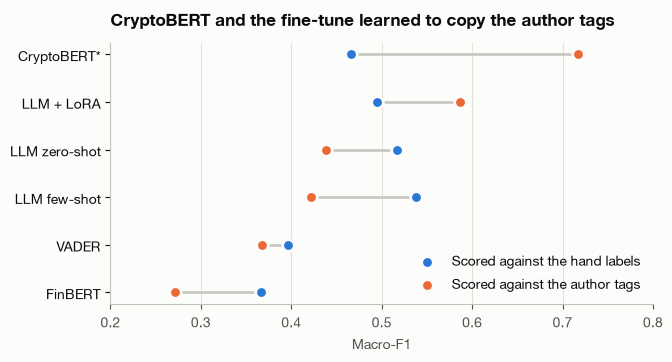

In [14]:
tags = overall.drop(index="author_tag")[["macro_f1", "macro_f1_vs_author_tags"]]
tags.columns = ["vs. hand labels", "vs. author tags"]
tags_order = tags["vs. author tags"].sort_values().index
y_tags = np.arange(len(tags_order))

fig, ax = plt.subplots(figsize=(7, 3.4))
for i, model in enumerate(tags_order):
    ax.plot(tags.loc[model], [i, i], color=GRAY, linewidth=2, zorder=1)
ax.scatter(tags.loc[tags_order, "vs. hand labels"], y_tags, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=2, label="Scored against the hand labels")
ax.scatter(tags.loc[tags_order, "vs. author tags"], y_tags, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=2, label="Scored against the author tags")
ax.set_yticks(y_tags, [MODELS[model] for model in tags_order])
ax.set_xlim(0.2, 0.8)
ax.set_xlabel("Macro-F1")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("CryptoBERT and the fine-tune learned to copy the author tags")
save(fig, "hand_vs_author_tags.png")

tags.loc[tags_order[::-1]].rename(index=MODELS).round(3)

## 6. The fine-tune's training curve

Training and validation loss from notebook 05. Both are measured against the author tags, so falling loss means the model got better at predicting those tags, not at reading sentiment.

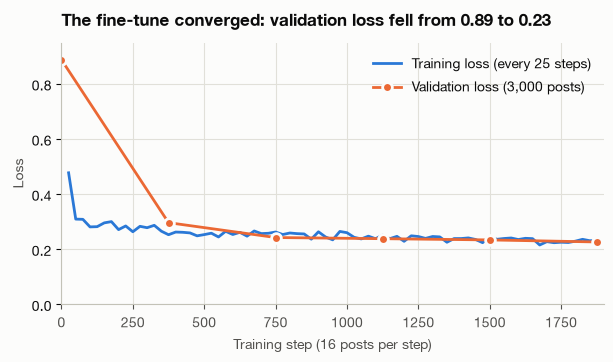

In [15]:
log = pd.read_csv(RESULTS_DIR / "lora_log.csv")
train_loss = log.dropna(subset=["train_loss"])
val_loss = log.dropna(subset=["val_loss"])

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(train_loss["step"], train_loss["train_loss"], color=BLUE, linewidth=2, label="Training loss (every 25 steps)")
ax.plot(val_loss["step"], val_loss["val_loss"], color=ORANGE, linewidth=2, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, label="Validation loss (3,000 posts)")
ax.set_xlim(0, 1900)
ax.set_ylim(0, 0.95)
ax.set_xlabel("Training step (16 posts per step)")
ax.set_ylabel("Loss")
ax.legend(loc="upper right")
ax.set_title("The fine-tune converged: validation loss fell from 0.89 to 0.23")
save(fig, "lora_training_loss.png")

## 7. Error analysis: the posts every model gets wrong

Each post is checked against the six models (the author tags are left out). How many models get each post wrong:

In [16]:
SIX_MODELS = [model for model in MODELS if model != "author_tag"]
answers = test.copy()
for model in SIX_MODELS:
    answers = answers.merge(load_preds(model, test).rename(columns={"pred_label": model}), on="post_id")
answers["models_wrong"] = sum((answers[model] != answers["label"]).astype(int) for model in SIX_MODELS)

answers["models_wrong"].value_counts().sort_index().rename_axis("models wrong").rename("posts")

models wrong
0    10
1    43
2    64
3    65
4    53
5    52
6    13
Name: posts, dtype: int64

In [17]:
print("Average number of models wrong per post:")
print(answers.groupby("slang")["models_wrong"].mean().rename({1: "slang-heavy", 0: "plain"}).round(2).to_string())

every_model_wrong = answers[answers["models_wrong"] == len(SIX_MODELS)]
print(f"\nEvery model is wrong on {len(every_model_wrong)} posts. Their hand labels:")
print(every_model_wrong["label"].value_counts().to_string())

Average number of models wrong per post:
slang
plain          3.05
slang-heavy    3.05

Every model is wrong on 13 posts. Their hand labels:
label
neutral    10
bearish     2
bullish     1


The slang-heavy posts that every model gets wrong:

In [18]:
columns = ["label", "author_label", "matched_terms", "cryptobert", "llm_zeroshot", "llm_fewshot", "llm_lora", "text"]
hardest = every_model_wrong[every_model_wrong["slang"] == 1][columns].copy()
hardest["text"] = hardest["text"].str.slice(0, 110)
with pd.option_context("display.max_colwidth", 120):
    display(hardest)

,label,author_label,matched_terms,cryptobert,llm_zeroshot,llm_fewshot,llm_lora,text
14,neutral,bearish,bags,bearish,bearish,bearish,bearish,millenial rh investors left holding some heavy ass bags
121,bullish,bearish,bags,bearish,bearish,bearish,bearish,-x there will be bags
142,neutral,bearish,whales,bearish,bearish,bearish,bearish,"this is probably going to bounce from the current level because you have people thinking this is support, whal"
223,neutral,bearish,bagholders,bearish,bearish,bearish,bearish,you want to see where sheetba price will be in 6 months? look at 6 months and still dead money! this is your f
274,bearish,neutral,hodl,bullish,bullish,neutral,bullish,"just hodl long with our , saitama, and 💎💎💎👐👐👐"
275,neutral,bearish,bagholder,bearish,bearish,bearish,bearish,"lol poor bagholder!!! thought the top was the bottom, now he lost 90% of his rent-money on a meme!"


Three patterns stand out:

- **Mocking other traders.** Posts that laugh at *bagholders* (people stuck holding a coin after it fell) were labeled neutral by hand, because they say nothing about where the price goes next. Every model reads them as bearish, and so did their authors. Whether mocking someone's losses is bearish is a judgment call the labeling guide does not settle.
- **Too little context.** *"-x there will be bags"* is hard to call without knowing what came before it.
- **Possible labeling slips.** A few hand labels look debatable in hindsight, such as *"just hodl long with our, saitama, and 💎💎💎👐👐👐"* (labeled bearish) and a long post predicting a drop "to 10k or below" (labeled neutral). With a single labeler, some slips are expected. The labels were not changed after seeing the models' answers, because that would tilt the scores toward those models.

Slang is not what makes a post hard: the average post is missed by 3.05 of the 6 models in both groups. The hard part is where neutral ends, since 10 of the 13 posts every model misses are neutral by hand.

## Summary

- **A prompted small LLM beats every baseline.** With no training, zero-shot (0.52) and few-shot (0.54) beat CryptoBERT (0.47) in 95% and 98% of resamples, even though CryptoBERT was trained on 2 million posts from this same dataset.
- **Fine-tuning on the author tags did not help.** The fine-tune (0.49) beats CryptoBERT in 85% of resamples but trails zero-shot in 74%, so it is within noise of both. It learned the tags: scored against them, its macro-F1 is 0.59, against 0.44 for zero-shot and 0.72 for CryptoBERT.
- **The author tags are poor sentiment labels.** They match the hand labels on 45% of posts, and about half the posts their authors tagged bullish or bearish are neutral by hand. A model trained on them learns to see an opinion in nearly every post.
- **Slang is not the hard part; neutral is.** Only FinBERT does clearly worse on slang (0.30 vs. 0.42 on plain posts), and the average post is missed by the same number of models in both groups. No model matches the hand labels' 53% neutral (the models answer neutral for 12% to 84% of posts), and 10 of the 13 posts every model misses are neutral by hand.
- **300 posts cannot separate the top models.** Each score's 95% range is about ±0.05, wider than the gaps between the three LLM runs.
- **Validation loss measures fit to the training labels.** The fine-tune's validation loss fell steadily (0.89 to 0.23), yet its test score did not improve, because both losses are measured against the author tags.